# Validating the simulated AGN catalog against SDSS

Checks the black hole masses, Eddington ratios and bolometric luminosities that
`QuasarHostMatch` assigns, against the SDSS DR7 quasar property catalog of
[Shen et al. (2011)](https://arxiv.org/abs/1006.5178), pulled from VizieR.

Compares two host catalogs: all galaxies (red hosts get $M_{\rm BH}$ from $M$-$\sigma$,
blue hosts from $M$-$M_*$) and red galaxies only. Both use the lognormal
Eddington ratio distribution of `QuasarHostMatch`.

In [1]:
import os, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table, vstack
from astropy.cosmology import FlatLambdaCDM
from astropy.units import Quantity

import slsim
from slsim.Pipelines.skypy_pipeline import SkyPyPipeline
from slsim.Pipelines import roman_speclite
from slsim.Deflectors.MassLightConnection.velocity_dispersion import (
    vel_disp_abundance_matching,
)
from slsim.Sources.SourceCatalogues.QuasarCatalog.quasar_pop import QuasarRate
from slsim.Sources.SourceCatalogues.QuasarCatalog.quasar_host_match import (
    QuasarHostMatch,
    L_EDDINGTON_PER_MSUN,
    BLACK_HOLE_MASS_RELATIONS,
    ERDF_LOCATION,
    ERDF_WIDTH,
    log_black_hole_mass,
    log_bolometric_luminosity,
)

warnings.filterwarnings("ignore")
roman_speclite.configure_roman_filters()

DATA_DIR = "../data"
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
sky_area = Quantity(2.0, "deg2")
skypy_config = os.path.join(
    os.path.split(os.path.dirname(slsim.__file__))[0], "data/SkyPy/roman-lsst-like.yml"
)

COLORS = {"all": "tab:blue", "red": "tab:red"}
LABELS = {"all": "all hosts", "red": "red hosts only"}

In [2]:
shen_path = os.path.join(DATA_DIR, "shen2011_dr7.fits")

if os.path.exists(shen_path):
    shen = Table.read(shen_path)
else:
    import pyvo

    tap = pyvo.dal.TAPService("https://tapvizier.cds.unistra.fr/TAPVizieR/tap")
    job = tap.submit_job(
        '''SELECT "z", "logLbol", "logBH", "logEdd", "iMAG"
           FROM "J/ApJS/194/45/catalog"
           WHERE "logBH" IS NOT NULL AND "logLbol" IS NOT NULL
             AND "iMAG" IS NOT NULL'''
    )
    job.run()
    job.wait(timeout=900)
    shen = job.fetch_result().to_table()
    shen.write(shen_path, overwrite=True)

for column in ["logBH", "logLbol", "logEdd", "iMAG"]:
    shen = shen[np.isfinite(shen[column])]
len(shen)

104746

In [3]:
hosts_path = os.path.join(DATA_DIR, f"hosts_{sky_area.value:g}deg2.fits")

if os.path.exists(hosts_path):
    hosts = Table.read(hosts_path)
else:
    pipeline = SkyPyPipeline(
        skypy_config=skypy_config, sky_area=sky_area, filters=None, cosmo=cosmo
    )
    red, blue = pipeline.red_galaxies, pipeline.blue_galaxies
    red["galaxy_type"], blue["galaxy_type"] = "red", "blue"
    hosts = vstack([red, blue], join_type="exact")
    hosts["vel_disp"] = vel_disp_abundance_matching(
        hosts, z_max=0.5, sky_area=sky_area, cosmo=cosmo
    )(np.log10(hosts["stellar_mass"]))
    hosts.write(hosts_path, overwrite=True)

len(hosts)

4700033

The SkyPy host catalog is overwhelmingly dwarf galaxies, which is what drives
the black hole masses low when blue hosts are allowed.

In [4]:
z, sigma = np.asarray(hosts["z"]), np.asarray(hosts["vel_disp"])
print(f"{'z bin':<10}{'N':>9}{'sigma p50':>11}{'p99':>7}{'max':>7}{'N(s>240)':>10}")
for lo, hi in [(0.2, 0.4), (0.4, 0.8), (0.8, 1.2), (1.2, 1.8), (1.8, 2.5), (2.5, 3.5)]:
    s = sigma[(z > lo) & (z < hi) & (sigma > 0)]
    print(f"{f'{lo}-{hi}':<10}{len(s):>9}{np.percentile(s, 50):>11.0f}"
          f"{np.percentile(s, 99):>7.0f}{s.max():>7.0f}{(s > 240).sum():>10}")

z bin             N  sigma p50    p99    max  N(s>240)
0.2-0.4      130058         29    117    321        14
0.4-0.8      420681         33    141    347       147
0.8-1.2      494513         36    162    352       482
1.2-1.8      724120         39    182    499      1568
1.8-2.5      755062         41    215    509      3764
2.5-3.5      933153         43    256    577     11929


In [5]:
quasar_rate = QuasarRate(
    skypy_config=skypy_config, cosmo=cosmo, sky_area=sky_area, noise=True,
    redshifts=np.linspace(0.001, 5.01, 100), use_qsogen_sed=False,
)
quasars = quasar_rate.quasar_sample(m_min=15, m_max=26, host_galaxy=False)

host_sets = {"all": hosts, "red": hosts[hosts["galaxy_type"] == "red"]}
matched = {}
for name, host_set in host_sets.items():
    matcher = QuasarHostMatch(quasars, host_set, rng=0, verbose=True)
    matched[name] = matcher.match()
    print(f"{name:<14} matched {len(matched[name])}  rejected {len(matcher.rejected_indices)}")

Matching quasars with host galaxies: 100%|██████████| 3619/3619 [00:03<00:00, 1115.54it/s]


defaults       matched 3619  rejected 0


Matching quasars with host galaxies: 100%|██████████| 3619/3619 [00:00<00:00, 10371.11it/s]

recommended    matched 3619  rejected 0


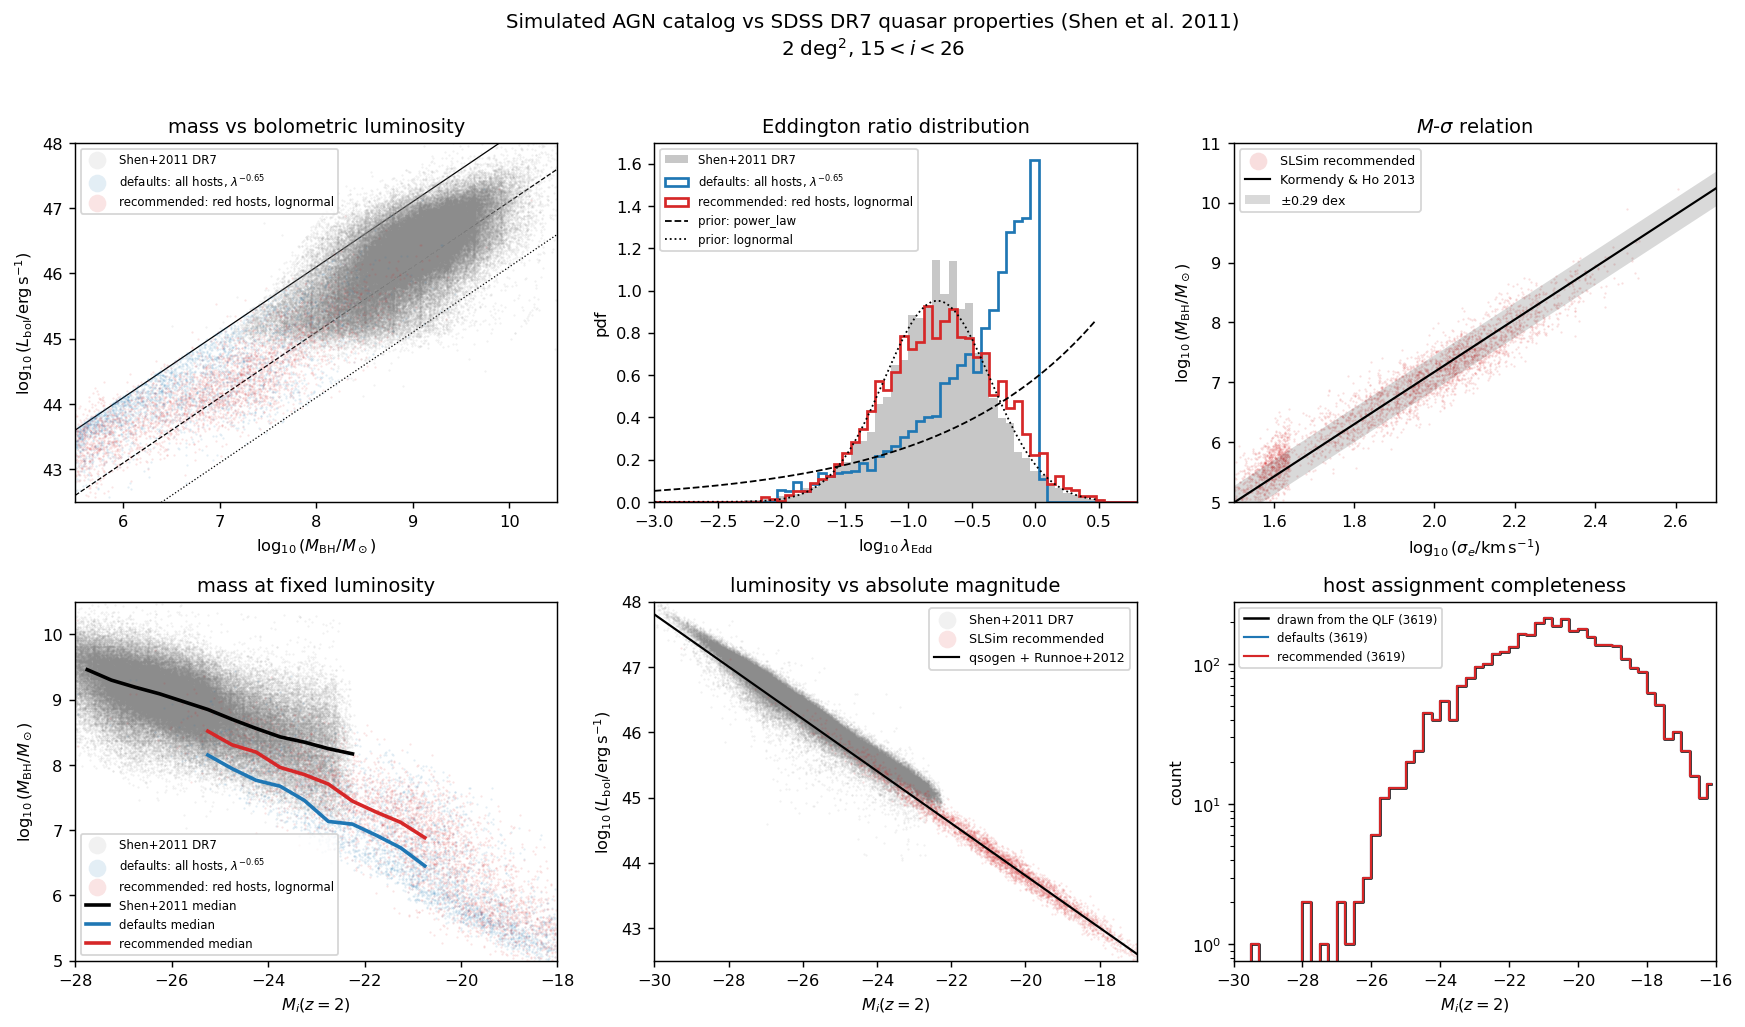

In [11]:
plt.rcParams.update({"font.size": 9, "figure.dpi": 130})
fig, ax = plt.subplots(2, 3, figsize=(13.5, 8))

def cloud(axis, x, y, color, label=None, alpha=0.12):
    axis.scatter(x, y, s=1.5, alpha=alpha, c=color, lw=0, rasterized=True, label=label)

a = ax[0, 0]
cloud(a, shen["logBH"], shen["logLbol"], "0.55", "Shen+2011 DR7")
for name, table in matched.items():
    cloud(a, table["black_hole_mass_exponent"], table["log_bolometric_luminosity"],
          COLORS[name], LABELS[name])
grid = np.linspace(5.5, 10.5, 10)
for ratio, style in zip([1.0, 0.1, 0.01], ["-", "--", ":"]):
    a.plot(grid, grid + np.log10(L_EDDINGTON_PER_MSUN * ratio), "k", ls=style,
           lw=0.7, zorder=0)
a.set(xlabel=r"$\log_{10}(M_{\rm BH}/M_\odot)$",
      ylabel=r"$\log_{10}(L_{\rm bol}/{\rm erg\,s^{-1}})$",
      xlim=(5.5, 10.5), ylim=(42.5, 48), title="mass vs bolometric luminosity")
a.legend(markerscale=8, fontsize=6.5, loc="upper left")

a = ax[0, 1]
bins = np.linspace(-3, 0.8, 60)
a.hist(shen["logEdd"], bins=bins, density=True, histtype="stepfilled",
       color="0.78", label="Shen+2011 DR7", zorder=0)
for name, table in matched.items():
    a.hist(np.log10(table["eddington_ratio"]), bins=bins, density=True,
           histtype="step", color=COLORS[name], lw=1.5, label=LABELS[name])
log_lam = np.linspace(bins[0], bins[-1], 500)
prior = np.exp(-0.5 * ((log_lam - ERDF_LOCATION) / ERDF_WIDTH) ** 2) / (
    ERDF_WIDTH * np.sqrt(2 * np.pi))
a.plot(log_lam, prior, "k:", lw=1, label="prior: lognormal")
a.set(xlabel=r"$\log_{10}\lambda_{\rm Edd}$", ylabel="pdf", xlim=(-3, 0.8),
      title="Eddington ratio distribution")
a.legend(fontsize=6.5)

a = ax[0, 2]
cloud(a, np.log10(matched["red"]["vel_disp"]),
      matched["red"]["black_hole_mass_exponent"], "tab:red",
      LABELS["red"], alpha=0.15)
grid = np.linspace(1.5, 2.7, 50)
mean, scatter = log_black_hole_mass(np.full(grid.shape, "red"), vel_disp=10**grid)
a.plot(grid, mean, "k-", lw=1.2, label="Kormendy & Ho 2013")
a.fill_between(grid, mean - scatter, mean + scatter, color="k", alpha=0.15, lw=0,
               label=rf"$\pm{scatter[0]:.2f}$ dex")
a.set(xlabel=r"$\log_{10}(\sigma_e/{\rm km\,s^{-1}})$",
      ylabel=r"$\log_{10}(M_{\rm BH}/M_\odot)$", xlim=(1.5, 2.7), ylim=(5, 11),
      title=r"$M$-$\sigma$ relation")
a.legend(markerscale=8, fontsize=7, loc="upper left")

a = ax[1, 0]
cloud(a, shen["iMAG"], shen["logBH"], "0.55", "Shen+2011 DR7")
for name, table in matched.items():
    cloud(a, table["M_i"], table["black_hole_mass_exponent"], COLORS[name],
          LABELS[name])
edges = np.arange(-28, -20, 0.5)
series = [(np.asarray(shen["iMAG"]), np.asarray(shen["logBH"]), "k", "Shen+2011")]
series += [(np.asarray(t["M_i"]), np.asarray(t["black_hole_mass_exponent"]),
            COLORS[n], n) for n, t in matched.items()]
for x, y, color, label in series:
    index = np.digitize(x, edges)
    centres = [0.5 * (edges[b - 1] + edges[b]) for b in range(1, len(edges))
               if (index == b).sum() > 20]
    medians = [np.median(y[index == b]) for b in range(1, len(edges))
               if (index == b).sum() > 20]
    a.plot(centres, medians, color=color, lw=2, label=label + " median")
a.set(xlabel=r"$M_i(z=2)$", ylabel=r"$\log_{10}(M_{\rm BH}/M_\odot)$",
      xlim=(-28, -18), ylim=(5, 10.5), title="mass at fixed luminosity")
a.legend(markerscale=8, fontsize=6.5, loc="lower left")

a = ax[1, 1]
cloud(a, shen["iMAG"], shen["logLbol"], "0.55", "Shen+2011 DR7")
cloud(a, matched["red"]["M_i"],
      matched["red"]["log_bolometric_luminosity"], "tab:red", LABELS["red"])
grid = np.linspace(-30, -17, 50)
a.plot(grid, log_bolometric_luminosity(grid), "k-", lw=1.2,
       label="Wu & Shen 2022 + Richards+2006 BC")
a.set(xlabel=r"$M_i(z=2)$", ylabel=r"$\log_{10}(L_{\rm bol}/{\rm erg\,s^{-1}})$",
      xlim=(-30, -17), ylim=(42.5, 48), title="luminosity vs absolute magnitude")
a.legend(markerscale=8, fontsize=7, loc="upper right")

a = ax[1, 2]
bins = np.linspace(-30, -16, 57)
centres = 0.5 * (bins[1:] + bins[:-1])
a.step(centres, np.histogram(quasars["M_i"], bins=bins)[0], where="mid",
       color="k", lw=1.4, label=f"drawn from the QLF ({len(quasars)})")
for name, table in matched.items():
    a.step(centres, np.histogram(table["M_i"], bins=bins)[0], where="mid",
           color=COLORS[name], lw=1.2, label=f"{name} ({len(table)})")
a.set_yscale("log")
a.set(xlabel=r"$M_i(z=2)$", ylabel="count", xlim=(-30, -16),
      title="host assignment completeness")
a.legend(fontsize=6.5)

fig.suptitle("Simulated AGN catalog vs SDSS DR7 quasar properties "
             f"(Shen et al. 2011)\n{sky_area.value:g} deg$^2$, $15<i<26$",
             fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("../figures/agn_catalog_validation.png", dpi=150, bbox_inches="tight")

The bright subset is the only range where SDSS DR7 and this catalog overlap,
so it is the only fair like-for-like comparison.

In [7]:
def percentiles(values):
    return np.round(np.nanpercentile(np.asarray(values), [16, 50, 84]), 2)

bright = (shen["iMAG"] > -26) & (shen["iMAG"] < -24)
print(f"{'':<34}{'log M_BH':<24}{'log lambda'}")
for name, table in matched.items():
    sub = (np.asarray(table["M_i"]) > -26) & (np.asarray(table["M_i"]) < -24)
    print(f"{name:<34}"
          f"{str(percentiles(np.asarray(table['black_hole_mass_exponent'])[sub])):<24}"
          f"{percentiles(np.log10(np.asarray(table['eddington_ratio'])[sub]))}")
print(f"{'Shen+2011 DR7':<34}{str(percentiles(shen['logBH'][bright])):<24}"
      f"{percentiles(shen['logEdd'][bright])}")

red = matched["red"]
residual = red["black_hole_mass_exponent"] - log_black_hole_mass(
    red["galaxy_type"], vel_disp=red["vel_disp"])[0]
print(f"\nM-sigma residual: mean {np.mean(residual):+.3f}, std {np.std(residual):.3f} dex "
      f"(input scatter {BLACK_HOLE_MASS_RELATIONS['red']['scatter']})")

check = matched["all"]
closure = check["log_bolometric_luminosity"] - (
    check["black_hole_mass_exponent"] + np.log10(L_EDDINGTON_PER_MSUN)
    + np.log10(check["eddington_ratio"])
)
print(f"L_bol = lambda * L_Edd(M_BH) closure: max |residual| "
      f"{np.abs(closure).max():.2e} dex")

                                  log M_BH                log lambda
defaults                          [7.55 7.91 8.36]        [-0.74 -0.33 -0.07]
recommended                       [7.9  8.32 8.74]        [-1.11 -0.77 -0.38]
Shen+2011 DR7                     [8.43 8.83 9.19]        [-1.23 -0.86 -0.51]

M-sigma residual: mean +0.020, std 0.295 dex (input scatter 0.29)
L_bol = lambda * L_Edd(M_BH) closure: max |residual| 7.11e-15 dex


In [8]:
pipeline = SkyPyPipeline(
        skypy_config=skypy_config, sky_area=sky_area, filters=None, cosmo=cosmo
    )
red, blue = pipeline.red_galaxies, pipeline.blue_galaxies
red["galaxy_type"], blue["galaxy_type"] = "red", "blue"
hosts = vstack([red, blue], join_type="exact")


In [5]:
hosts_extended = hosts.copy()
hosts_extended["vel_disp"] = vel_disp_abundance_matching(
    hosts_extended, z_max=.5, sky_area=sky_area, cosmo=cosmo
)(np.log10(hosts_extended["stellar_mass"]))
hosts_extended

z,M,coeff,ellipticity,physical_size,stellar_mass,angular_size,mag_F062,mag_F087,mag_F106,mag_F129,mag_F158,mag_F184,mag_F146,mag_F213,mag_g,mag_r,mag_i,mag_z,mag_y,galaxy_type,vel_disp
,,,,kpc,,arcsec,,,,,,,,,,,,,,,
float64,float64,float64[5],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bytes4,float64
1.97517496695474,-21.017985933501862,0.05296303823855121 .. 0.0013194934270625625,0.2763924724744557,2.1347152217666183,162793174846.98724,0.2546784384632512,26.376361297853393,25.71137018470816,24.893500220409692,23.780048164656506,23.103903895479682,22.743527441333548,23.44317017754925,22.495392275002253,26.503846408200026,26.35930589932424,26.26055274673284,25.76333333222592,25.225046879556302,red,171.12649087073325
1.3584733301845542,-21.952739059077444,0.12488652376233866 .. 0.0021922396939358956,0.20330238586490473,5.633179934900848,389024406419.59674,0.6695737038397804,24.585227227764868,23.039928929526347,21.941375396166805,21.325240425398,20.89381331279936,20.608926169749296,21.13863123795548,20.37434594490726,25.286274688031227,24.84052555589512,23.74436003867295,23.1669487318201,22.388519874866255,red,227.9372544545678
0.776365342020974,-21.828741088301005,0.030089015374453913 .. 0.000218928858760186,0.3434563426551313,5.637691972968875,376382241987.7108,0.7587253432678241,22.150031542576578,20.54082827119901,20.031036289580797,19.6574143299663,19.336016488295627,19.08992636431158,19.5150691991038,18.998324798420917,23.803892221758588,22.358580699044808,21.14687751768669,20.52011031691824,20.23162038709365,red,224.4155840413031
1.1312785754515686,-20.832042813727163,0.13519270401737946 .. 0.0017717568447724258,0.24100029536112175,2.040498504265487,129801499861.24414,0.24838716158893942,24.618625835283446,23.145882741281923,22.35437333891671,21.85973874383346,21.489443197736314,21.24122061526569,21.705985899465105,20.965490121536853,25.28654925452627,24.726185802909292,23.958372221976397,23.175397874340213,22.594593499554882,red,159.3183832584099
1.7453958106339933,-17.746453364690115,0.29026330306995113 .. 0.0012754360530505362,0.16148005889584646,0.31705740235510477,6474327584.53354,0.037487785691661314,28.092964595854458,27.857300612777056,27.280910004185554,26.53987029760864,26.066902398247546,25.723052016150152,26.31585138415171,25.46796992290518,28.150257619143172,28.08130467455103,28.06618355752776,27.860760307323755,27.63874134892532,red,47.08249061074688
1.2129201132429674,-17.415667252632943,0.16234516197860918 .. 0.0009353247310897524,0.3434151387786254,0.10922733255858981,6304275728.972049,0.013150009053607485,28.629056890863104,26.981659054881177,26.007647017737312,25.444687004421993,25.02638964047088,24.749300427530933,25.259307146210176,24.47135572877817,29.55580671776393,28.832512268732508,27.812182932134988,27.05568317457815,26.33666888299316,red,46.127586407111096
0.5288558850009432,-21.13592608877473,0.11550197858201179 .. 0.0009007189426015368,0.22859231410163952,2.428186686311572,173264653032.69705,0.38628967258203295,21.09737326027145,20.035544163405337,19.634175263989807,19.30169444264965,18.97626630071314,18.830304379733402,19.174687100466645,18.734914516312916,22.577329704246754,21.227777858780957,20.38650723328016,20.02065010453693,19.778084399288165,red,173.96785033182542
4.002929449597768,-20.316526893375976,0.01322829618179328 .. 0.00025829362086448015,0.15831587120688725,2.30460518346102,90171052896.12953,0.3315750316260271,29.955261791660583,29.805550979793935,29.539666702368955,29.047424675326653,27.635489832860152,26.87863841485288,27.883664718045637,25.88413147533239,30.635163327130158,29.916432930174523,29.929546404272067,29.753101554511687,29.695669181459145,red,141.36591201745054


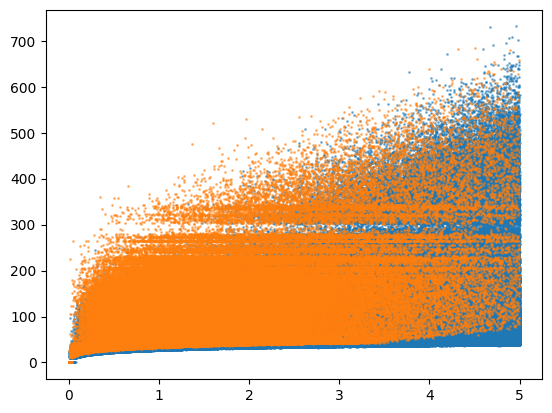

In [8]:
# plt.scatter(hosts_extended["z"], hosts_extended["vel_disp"], s=1, alpha=0.1)
blue_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "blue"]
plt.scatter(blue_galaxies["z"], blue_galaxies["vel_disp"], s=1, alpha=0.5)
red_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "red"]
plt.scatter(red_galaxies["z"], red_galaxies["vel_disp"], s=1, alpha=0.5)

In [9]:
len(blue_galaxies), len(red_galaxies)

(4420143, 279890)

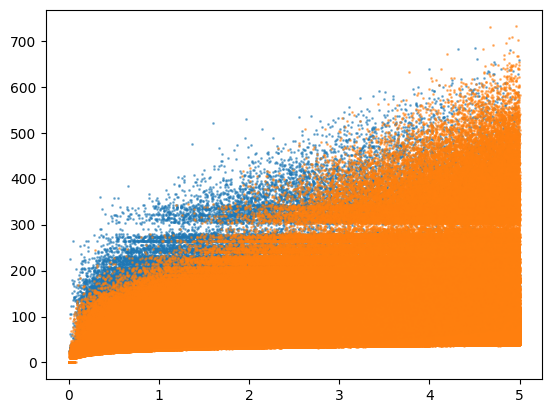

In [10]:
# plt.scatter(hosts_extended["z"], hosts_extended["vel_disp"], s=1, alpha=0.1)
red_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "red"]
plt.scatter(red_galaxies["z"], red_galaxies["vel_disp"], s=1, alpha=0.5)
blue_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "blue"]
plt.scatter(blue_galaxies["z"], blue_galaxies["vel_disp"], s=1, alpha=0.5)

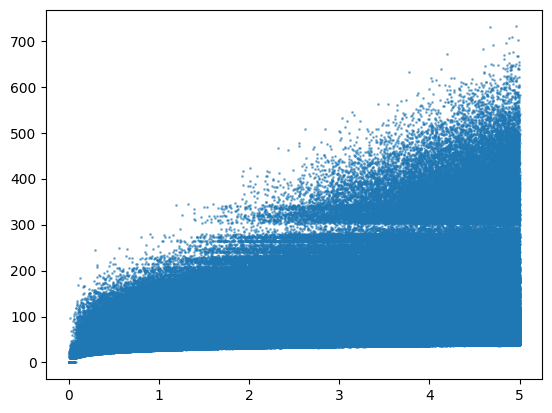

In [11]:
# plt.scatter(hosts_extended["z"], hosts_extended["vel_disp"], s=1, alpha=0.1)
# red_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "red"]
# plt.scatter(red_galaxies["z"], red_galaxies["vel_disp"], s=1, alpha=0.5)
blue_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "blue"]
plt.scatter(blue_galaxies["z"], blue_galaxies["vel_disp"], s=1, alpha=0.5)

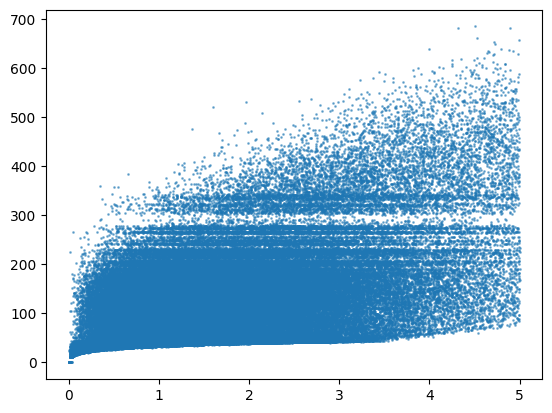

In [12]:
# plt.scatter(hosts_extended["z"], hosts_extended["vel_disp"], s=1, alpha=0.1)
red_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "red"]
plt.scatter(red_galaxies["z"], red_galaxies["vel_disp"], s=1, alpha=0.5)
# blue_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "blue"]
# plt.scatter(blue_galaxies["z"], blue_galaxies["vel_disp"], s=1, alpha=0.5)

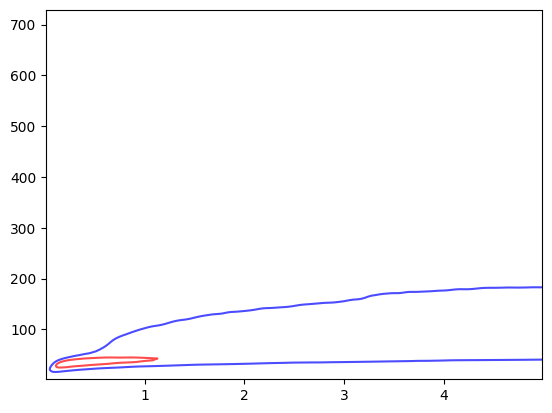

In [23]:
# contours of the red and blue galaxies in the z vs vel_disp plane

import numpy as np
import matplotlib.pyplot as plt

# Adjust 'bins' to change the resolution/smoothness of the contours
bins = 200 

for gal_type, color in [("red", "red"), ("blue", "blue")]:
    subset = hosts_extended[hosts_extended["galaxy_type"] == gal_type]
    
    # 1. Instantly calculate density grid via NumPy 2D histogram
    H, xedges, yedges = np.histogram2d(subset["z"], subset["vel_disp"], bins=bins)
    H = np.log10(H + 1)  # Log scale for better visualization

    # make it smoother by applying a Gaussian filter
    from scipy.ndimage import gaussian_filter
    H = gaussian_filter(H, sigma=2)
    
    # 2. Get bin centers for plotting
    x_centers = (xedges[:-1] + xedges[1:]) / 2
    y_centers = (yedges[:-1] + yedges[1:]) / 2
    
    # 3. Plot contours (H.T transposes the matrix to align with x,y coords)
    # Increase 'levels' to show more contour rings
    plt.contour(x_centers, y_centers, H.T, colors=color, alpha=0.7, levels=[2])

plt.show()

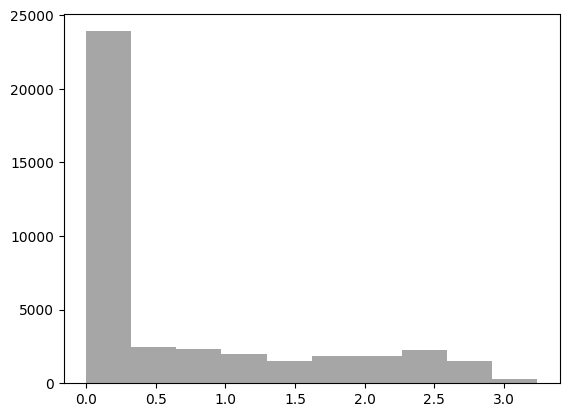

In [20]:
plt.hist(H.flatten(), bins=10, color='gray', alpha=0.7);